# Model Building & Evaluation — Customer Churn Prediction
**Project:** Customer Churn Prediction & Retention Intelligence Platform (DEPI — Group 2)  
**Models:** K-Nearest Neighbors (KNN) & Support Vector Machine (SVM)  

This notebook contains the complete, leakage-safe modeling workflow:
1. **Load Cleaned Data** (`cleaned_data.csv`)
2. **Stratified 80/20 Train/Test Split** (`random_state=42`) & export separate `test_data.csv`
3. **Custom Feature Engineering & Preprocessing Pipeline** (`FeatureEngineer` + `ColumnTransformer` -> 54 features)
4. **Hyperparameter Tuning (5-Fold Stratified CV)** using `GridSearchCV` (KNN: 20 settings, SVM: 24 settings, selected by CV F1)
5. **Held-Out Test Set Evaluation** (Accuracy, Precision, Recall, F1, ROC-AUC)
6. **Visualizations** (Model Comparison & Confusion Matrices)
7. **Save Model & Preprocessor** (`customer_churn_model.pkl`, `customer_churn_knn_model.pkl`, `customer_churn_preprocessor.pkl`) + Inference Check

## 1. Imports & Load Cleaned Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
df = pd.read_csv("cleaned_data.csv")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
print(f"Loaded cleaned_data.csv: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Churn distribution:\n", df["Churn"].value_counts())

Loaded cleaned_data.csv: 7,043 rows x 20 columns
Churn distribution:
 Churn
0    5174
1    1869
Name: count, dtype: int64


## 2. Stratified 80/20 Train / Test Split (Separate Test File)

In [2]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Save held-out test set separately so it stays isolated from training
test_df = X_test_raw.copy()
test_df["Churn"] = y_test
test_df.to_csv("test_data.csv", index=False)

print(f"Training set: {X_train_raw.shape[0]:,} rows (churn rate: {y_train.mean():.3%})")
print(f"Test set:     {X_test_raw.shape[0]:,} rows (churn rate: {y_test.mean():.3%})")
print("Saved held-out test set to test_data.csv")

Training set: 5,634 rows (churn rate: 26.535%)
Test set:     1,409 rows (churn rate: 26.544%)
Saved held-out test set to test_data.csv


## 3. Feature Engineering & Preprocessing Pipeline (Leakage-Safe)

In [3]:
SERVICE_COLUMNS = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
]
TENURE_BINS = [-1, 12, 24, 48, 72]
TENURE_LABELS = ["0-12m", "13-24m", "25-48m", "49-72m"]
REQUIRED_COLUMNS = ["tenure", "MonthlyCharges", "TotalCharges", "PaymentMethod", "Contract", *SERVICE_COLUMNS]
ENGINEERED_COLUMNS = [
    "AvgMonthlySpend", "PriceHikeRatio", "TotalServicesCount",
    "IsAutoPayment", "HasHighRiskContract", "TenureCohort",
]


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless row-wise feature engineering with column-order alignment."""

    def __init__(self, epsilon: float = 1e-5, neutral_ratio_at_zero_tenure: float = 1.0):
        self.epsilon = epsilon
        self.neutral_ratio_at_zero_tenure = neutral_ratio_at_zero_tenure

    def fit(self, X: pd.DataFrame, y=None):
        self._validate(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        self._validate(X)
        expected = getattr(self, "feature_names_in_", None)
        if expected is not None:
            df = X.loc[:, list(expected)].copy()
        else:
            df = X.copy()

        df["AvgMonthlySpend"] = df["TotalCharges"] / (df["tenure"] + 1)
        df["PriceHikeRatio"] = df["MonthlyCharges"] / (df["AvgMonthlySpend"] + self.epsilon)
        if self.neutral_ratio_at_zero_tenure is not None:
            df.loc[df["tenure"] == 0, "PriceHikeRatio"] = self.neutral_ratio_at_zero_tenure
        df["TotalServicesCount"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1).astype(int)
        df["IsAutoPayment"] = df["PaymentMethod"].astype(str).str.contains("automatic", case=False, na=False).astype(int)
        df["HasHighRiskContract"] = (df["Contract"] == "Month-to-month").astype(int)
        df["TenureCohort"] = pd.cut(df["tenure"], bins=TENURE_BINS, labels=TENURE_LABELS, right=True).astype(str)
        return df

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.feature_names_in_) + ENGINEERED_COLUMNS, dtype=object)

    @staticmethod
    def _validate(X: pd.DataFrame):
        missing = [c for c in REQUIRED_COLUMNS if c not in X.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")


NUMERICAL_COLUMNS = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "PriceHikeRatio", "TotalServicesCount"]
CATEGORICAL_COLUMNS = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "TenureCohort",
]
BINARY_COLUMNS = ["SeniorCitizen", "IsAutoPayment", "HasHighRiskContract"]


def build_preprocessing_pipeline() -> Pipeline:
    ct = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERICAL_COLUMNS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLUMNS),
            ("bin", "passthrough", BINARY_COLUMNS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    ct.set_output(transform="pandas")
    return Pipeline([("feature_engineer", FeatureEngineer()), ("column_transformer", ct)])


preprocessor = build_preprocessing_pipeline()
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)
print(f"Processed shape -> Train: {X_train_proc.shape}, Test: {X_test_proc.shape}")

Processed shape -> Train: (5634, 54), Test: (1409, 54)


## 4. Hyperparameter Tuning (5-Fold Stratified CV — Training Data Only)

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

# 1) KNN Grid Search (20 candidates -> 100 fold fits)
knn_pipe = Pipeline([("preprocess", build_preprocessing_pipeline()), ("model", KNeighborsClassifier(n_jobs=1, algorithm="brute"))])
knn_grid = {
    "model__n_neighbors": [1, 5, 11, 21, 41],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_search = GridSearchCV(knn_pipe, knn_grid, scoring=scoring, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
knn_search.fit(X_train_raw, y_train)
print("Best KNN params:", knn_search.best_params_, "| Mean CV F1:", round(knn_search.best_score_, 4))

# 2) SVM Grid Search (24 candidates -> 120 fold fits)
svm_pipe = Pipeline([("preprocess", build_preprocessing_pipeline()), ("model", SVC(cache_size=512, random_state=RANDOM_STATE))])
svm_grid = [
    {"model__kernel": ["linear"], "model__C": [0.01, 0.1, 1], "model__class_weight": [None, "balanced"]},
    {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1], "model__class_weight": [None, "balanced"]},
]
svm_search = GridSearchCV(svm_pipe, svm_grid, scoring=scoring, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
svm_search.fit(X_train_raw, y_train)
print("Best SVM params:", svm_search.best_params_, "| Mean CV F1:", round(svm_search.best_score_, 4))

Best KNN params: {'model__n_neighbors': 41, 'model__p': 1, 'model__weights': 'uniform'} | Mean CV F1: 0.6076


Best SVM params: {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf'} | Mean CV F1: 0.6307


## 5. Held-Out Test Set Evaluation

In [5]:
def evaluate_model(name, pipe, X_tr, y_tr, X_te, y_te):
    pred_tr = pipe.predict(X_tr)
    pred_te = pipe.predict(X_te)
    score_te = pipe.predict_proba(X_te)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_te)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred_te),
        "Precision": precision_score(y_te, pred_te),
        "Recall": recall_score(y_te, pred_te),
        "F1 Score": f1_score(y_te, pred_te),
        "ROC-AUC": roc_auc_score(y_te, score_te),
        "Train F1": f1_score(y_tr, pred_tr),
        "F1 Gap": f1_score(y_tr, pred_tr) - f1_score(y_te, pred_te),
    }, pred_te


knn_metrics, knn_pred = evaluate_model("KNN", knn_search.best_estimator_, X_train_raw, y_train, X_test_raw, y_test)
svm_metrics, svm_pred = evaluate_model("SVM", svm_search.best_estimator_, X_train_raw, y_train, X_test_raw, y_test)

results_df = pd.DataFrame([knn_metrics, svm_metrics]).set_index("Model")
display(results_df.round(4))

print("\n=== Classification Report: SVM (Recommended for Churn Recall) ===")
print(classification_report(y_test, svm_pred, target_names=["Stay (0)", "Churn (1)"]))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Train F1,F1 Gap
Model,,,,,,,
KNN,0.7906,0.6106,0.5829,0.5964,0.8392,0.6268,0.0304
SVM,0.7502,0.5189,0.8075,0.6318,0.8277,0.6559,0.0241



=== Classification Report: SVM (Recommended for Churn Recall) ===
              precision    recall  f1-score   support

    Stay (0)       0.91      0.73      0.81      1035
   Churn (1)       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



## 6. Model Comparison & Confusion Matrices

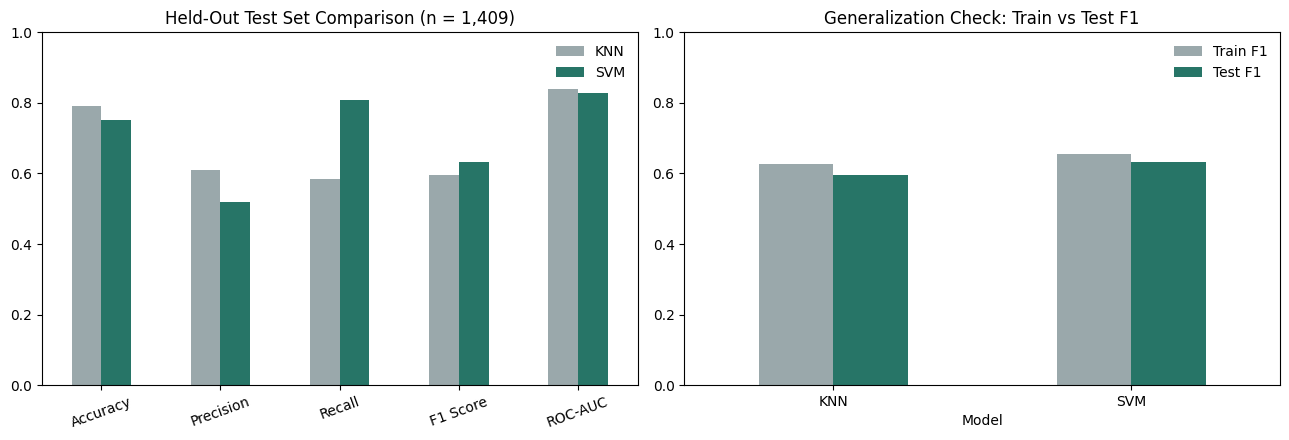

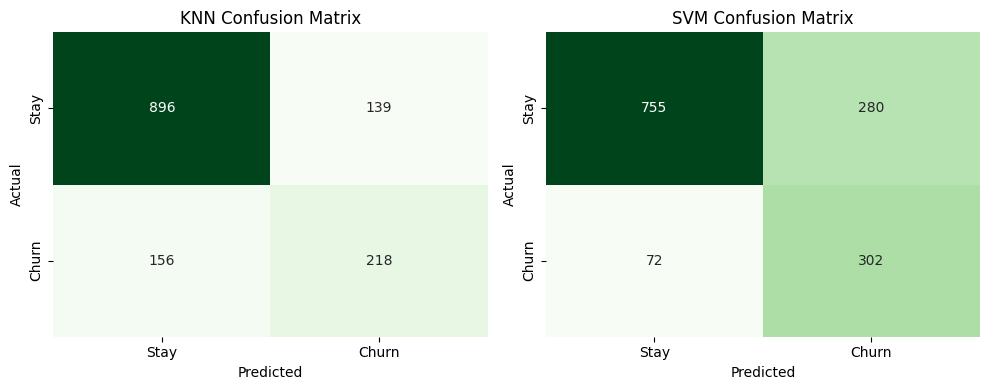

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Bar chart of test metrics
metrics_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
results_df[metrics_cols].T.plot(kind="bar", ax=axes[0], color=["#9aa8ab", "#277567"])
axes[0].set_title("Held-Out Test Set Comparison (n = 1,409)")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(frameon=False)

# Train vs Test F1
results_df[["Train F1", "F1 Score"]].plot(kind="bar", ax=axes[1], color=["#9aa8ab", "#277567"])
axes[1].set_title("Generalization Check: Train vs Test F1")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Train F1", "Test F1"], frameon=False)

plt.tight_layout()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("KNN", knn_pred), ("SVM", svm_pred)]):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
                xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. Save Model & Preprocessor (.pkl) + Inference Verification

In [7]:
# Save recommended end-to-end SVM pipeline, KNN pipeline, and fitted preprocessor
joblib.dump(svm_search.best_estimator_, "customer_churn_model.pkl")
joblib.dump(knn_search.best_estimator_, "customer_churn_knn_model.pkl")
joblib.dump(preprocessor, "customer_churn_preprocessor.pkl")
print("Saved: customer_churn_model.pkl, customer_churn_knn_model.pkl, customer_churn_preprocessor.pkl")

# Reload and verify on the separate test_data.csv file
loaded_model = joblib.load("customer_churn_model.pkl")
test_check = pd.read_csv("test_data.csv")
sample_X = test_check.drop(columns=["Churn"]).head(5)
sample_y = test_check["Churn"].head(5).tolist()
preds = loaded_model.predict(sample_X).tolist()
print("Sample actual labels:   ", sample_y)
print("Sample model predictions:", preds)

Saved: customer_churn_model.pkl, customer_churn_knn_model.pkl, customer_churn_preprocessor.pkl
Sample actual labels:    [0, 0, 0, 0, 0]
Sample model predictions: [0, 1, 0, 1, 0]
